# Notebook 02 — Experiments: what drives a high income?

**Mathematics & Statistics for Machine Learning — Albert School, MSc 1** · Lucas, Manuel, Amine

**Research question.** Is education the main driver of earning more than $50K a year, or do other factors such as marital status, age and hours worked matter more?

**Starting hypothesis.** Education is the number-one factor.

This notebook uses the CART built in notebook 01 (`src/cart.py`) and compares it with `sklearn.tree.DecisionTreeClassifier` on **the same splits**. The test set is used **once**, in section 6.

## 0. Setup

In [1]:
import os
from pathlib import Path

# Run from the repository root so that `src` can be imported and `data/` is shared.
if Path.cwd().name == "notebooks":
    os.chdir("..")

import time

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             roc_auc_score, confusion_matrix)

from src.data import SEED, DROPPED_COLUMNS, load_adult, get_splits, preprocess
from src.cart import CARTClassifier

np.random.seed(SEED)
sns.set_theme(style="whitegrid")
FIG_DIR = Path("report/figures")
FIG_DIR.mkdir(parents=True, exist_ok=True)

## 1. Problem and data

- **Source.** UCI *Adult* (1994 US Census extract by Barry Becker), also on Kaggle: https://www.kaggle.com/datasets/uciml/adult-census-income. The code loads the same data from OpenML (`adult`, version 2, 48,842 rows) and caches it in `data/` (ignored by git: the data is not redistributed).
- **Target.** `income > 50K` (1) or `<= 50K` (0), binary classification.
- **Features.** 6 numeric (`age`, `education-num`, `capital-gain`, `capital-loss`, `hours-per-week`, `fnlwgt`) and 8 categorical (`workclass`, `education`, `marital-status`, `occupation`, `relationship`, `race`, `sex`, `native-country`).
- **Dropped.** `fnlwgt` is a census sampling weight, not a property of the person. `education` is the same information as `education-num` (one integer per diploma level): keeping both would split the importance of education in two and bias the answer to our question.

In [2]:
X_raw, y_all = load_adult()
df = X_raw.assign(income=np.where(y_all == 1, ">50K", "<=50K"))
print(df.shape)
display(df.head())

(48842, 13)


,age,workclass,education-num,marital-status,occupation,relationship,race,sex,capital-gain,capital-loss,hours-per-week,native-country,income
0,25,Private,7,Never-married,Machine-op-inspct,Own-child,Black,Male,0,0,40,United-States,<=50K
1,38,Private,9,Married-civ-spouse,Farming-fishing,Husband,White,Male,0,0,50,United-States,<=50K
2,28,Local-gov,12,Married-civ-spouse,Protective-serv,Husband,White,Male,0,0,40,United-States,>50K
3,44,Private,10,Married-civ-spouse,Machine-op-inspct,Husband,Black,Male,7688,0,40,United-States,>50K
4,18,NaN,10,Never-married,NaN,Own-child,White,Female,0,0,30,United-States,<=50K


## 2. Exploration

Exploration uses the full dataset only to *describe* it; no modelling choice below depends on the test rows.

In [3]:
print(f"share of >50K: {y_all.mean():.3f}")
missing = X_raw.isna().sum()
display(pd.DataFrame({"missing": missing, "share": missing / len(X_raw)})[missing > 0].round(3))
miss_rate = pd.Series({c: y_all[X_raw[c].isna()].mean() for c in missing[missing > 0].index})
print("share of >50K among rows where the value is missing:")
print(miss_rate.round(3))

share of >50K: 0.239


,missing,share
workclass,2799,0.057
occupation,2809,0.058
native-country,857,0.018


share of >50K among rows where the value is missing:
workclass         0.095
occupation        0.094
native-country    0.257
dtype: float64


- The classes are **imbalanced**: 24 % of >50K. Accuracy alone will be misleading (section 4).
- Missing values touch only three categorical features (`workclass`, `occupation`, `native-country`, 2–6 %). Rows with a missing occupation are much **less** often >50K than average: "missing" carries information (people out of work often leave it blank), so dropping or imputing these rows would hide a signal. They become a category `"Unknown"`.

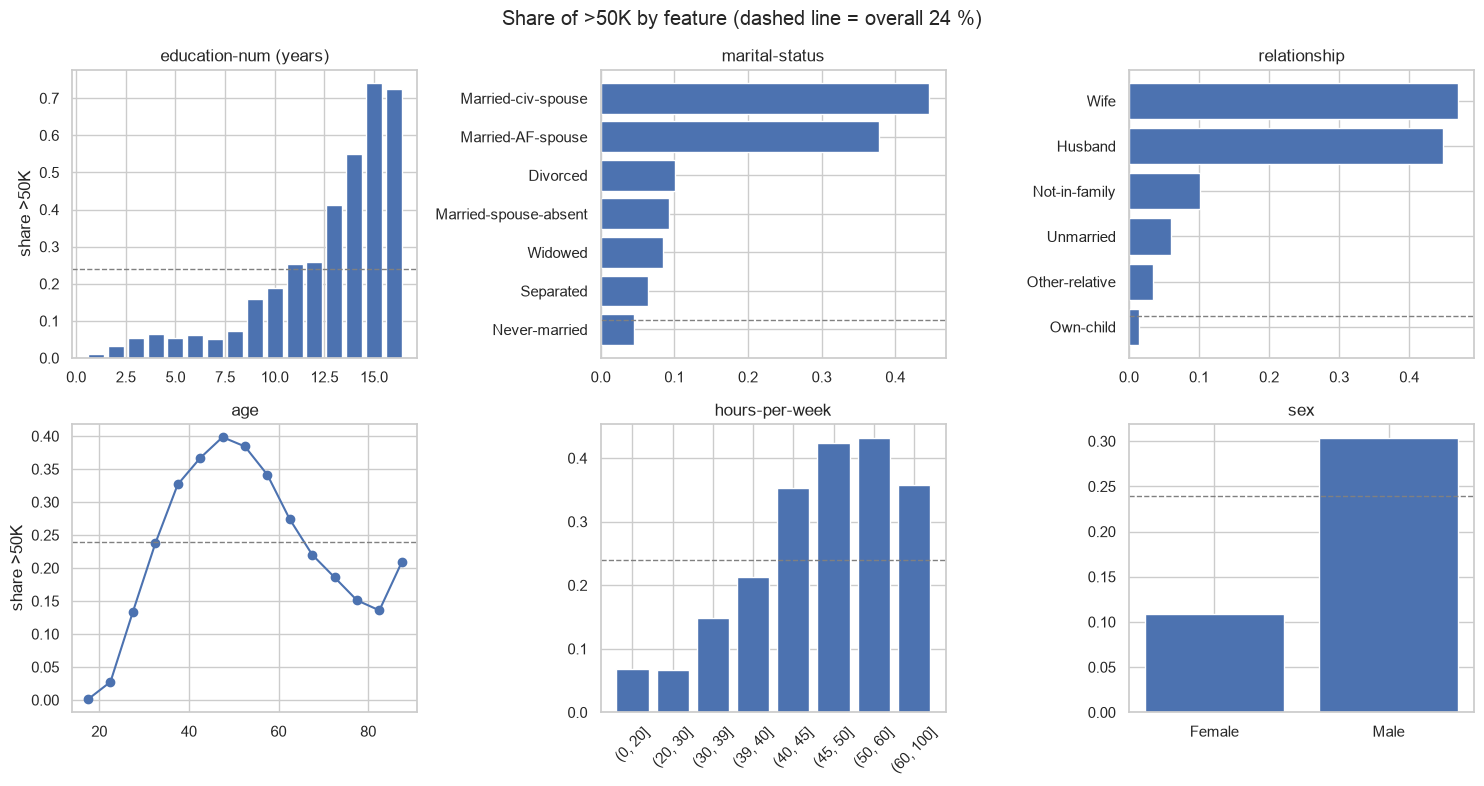

In [4]:
fig, axes = plt.subplots(2, 3, figsize=(15, 8))
rate = lambda col: df.groupby(col, observed=True)["income"].apply(lambda s: (s == ">50K").mean())

r = rate("education-num"); axes[0, 0].bar(r.index, r.values); axes[0, 0].set(title="education-num (years)", ylabel="share >50K")
r = rate("marital-status").sort_values(); axes[0, 1].barh(r.index, r.values); axes[0, 1].set(title="marital-status")
r = rate("relationship").sort_values(); axes[0, 2].barh(r.index, r.values); axes[0, 2].set(title="relationship")
r = df.groupby(pd.cut(df["age"], range(15, 95, 5)), observed=True)["income"].apply(lambda s: (s == ">50K").mean())
axes[1, 0].plot([i.mid for i in r.index], r.values, marker="o"); axes[1, 0].set(title="age", ylabel="share >50K")
r = df.groupby(pd.cut(df["hours-per-week"], [0, 20, 30, 39, 40, 45, 50, 60, 100]), observed=True)["income"].apply(lambda s: (s == ">50K").mean())
axes[1, 1].bar([str(i) for i in r.index], r.values); axes[1, 1].tick_params(axis="x", rotation=45); axes[1, 1].set(title="hours-per-week")
r = rate("sex"); axes[1, 2].bar(r.index, r.values); axes[1, 2].set(title="sex")
for ax in axes.flat:
    ax.axhline(y_all.mean(), color="grey", ls="--", lw=1)
fig.suptitle("Share of >50K by feature (dashed line = overall 24 %)")
fig.tight_layout(); fig.savefig(FIG_DIR / "exploration.png", dpi=150); plt.show()

In [5]:
# How strongly is each original feature linked to the target on its own? Cramér's V (0 = none, 1 = perfect).
def cramers_v(a, b):
    ct = pd.crosstab(a, b).to_numpy()
    n = ct.sum()
    expected = ct.sum(1, keepdims=True) * ct.sum(0, keepdims=True) / n
    chi2 = ((ct - expected) ** 2 / expected).sum()
    return np.sqrt(chi2 / (n * (min(ct.shape) - 1)))

binned = X_raw.drop(columns=DROPPED_COLUMNS, errors="ignore").copy()
for c in binned.select_dtypes("number"):
    if c.startswith("capital"):
        binned[c] = binned[c] > 0          # mostly zeros: "has capital income or not"
    elif binned[c].nunique() > 10:
        binned[c] = pd.qcut(binned[c], 10, duplicates="drop")
v = pd.Series({c: cramers_v(binned[c].astype(str), y_all) for c in binned}).sort_values(ascending=False)
display(v.round(3).to_frame("Cramér's V with income"))

,Cramér's V with income
relationship,0.454
marital-status,0.448
education-num,0.355
occupation,0.346
age,0.319
hours-per-week,0.274
capital-gain,0.266
sex,0.215
workclass,0.164
capital-loss,0.136


Taken **one at a time**, `relationship` and `marital-status` are more strongly linked to income than education. Education comes right after, ahead of age and hours worked. This is a first hint against our hypothesis, but it only looks at features in isolation: the tree will tell us what remains once all features compete.

`relationship` and `marital-status` overlap a lot ("Husband"/"Wife" ⇔ "Married-civ-spouse"): we will treat them together as the **family situation**.

## 3. Preparation and protocol

| Step | Choice | Why |
|---|---|---|
| Split | stratified 60 / 20 / 20, `SEED = 42` | train to learn, validation to tune, test **once** at the end; stratification keeps 24 % of >50K in each set |
| Missing values | category `"Unknown"` | they are informative (section 2) and only categorical |
| Encoding | one-hot, **columns fixed on the train set** then applied to validation and test | no information from validation/test enters the preparation |
| Scaling | none | a tree compares a feature to a threshold: rescaling moves the threshold, not the partition |

`get_splits()` splits the **raw** data first and encodes afterwards: that order is what prevents leakage.

In [6]:
splits, feature_names = get_splits()
X_train, y_train = splits["X_train"], splits["y_train"]
X_val, y_val = splits["X_val"], splits["y_val"]
X_test, y_test = splits["X_test"], splits["y_test"]
for key in ("train", "val", "test"):
    print(f"{key:5s}: {splits[f'X_{key}'].shape}, share of >50K = {splits[f'y_{key}'].mean():.3f}")

train: (29304, 91), share of >50K = 0.239
val  : (9769, 91), share of >50K = 0.239
test : (9769, 91), share of >50K = 0.239


## 4. Baseline and metrics

The simplest model always predicts the majority class "<=50K".

In [7]:
def scores(y_true, y_pred, proba=None):
    out = {"accuracy": accuracy_score(y_true, y_pred),
           "precision": precision_score(y_true, y_pred, zero_division=0),
           "recall": recall_score(y_true, y_pred),
           "F1": f1_score(y_true, y_pred)}
    if proba is not None:
        out["ROC AUC"] = roc_auc_score(y_true, proba)
    return out

baseline = scores(y_val, np.zeros_like(y_val), np.zeros(len(y_val)))
display(pd.DataFrame([baseline], index=["always <=50K (validation)"]).round(3))

,accuracy,precision,recall,F1,ROC AUC
always <=50K (validation),0.761,0.0,0.0,0.0,0.5


The baseline already has **76 % accuracy** while it never finds a single high earner (recall and F1 = 0). We therefore report:
- **F1** (main metric for tuning): harmonic mean of precision and recall on the >50K class, insensitive to the many easy "<=50K";
- **precision** (of those predicted >50K, how many really are) and **recall** (of the real >50K, how many we find), to see which kind of error dominates;
- **ROC AUC**: quality of the *ranking* by `predict_proba`, independent of the 0.5 threshold;
- **accuracy**, for reference only, and the **confusion matrix**.

## 5. Choosing the depth (validation set)

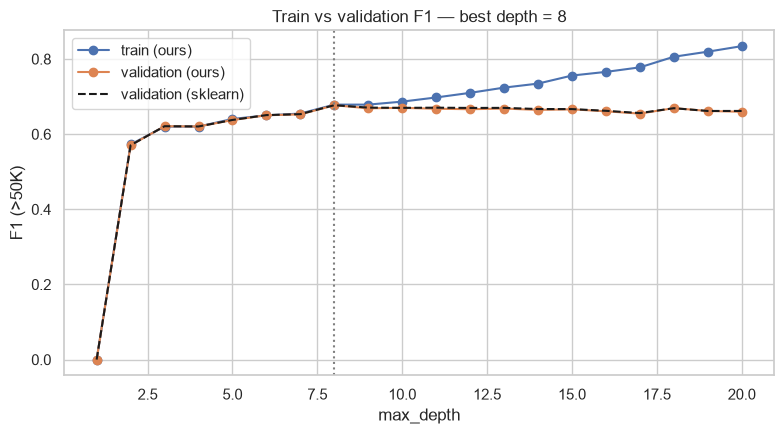

,train F1 (ours),val F1 (ours),val F1 (sklearn),val AUC (ours),leaves
depth,,,,,
1,0.000,0.000,0.000,0.762,2
2,0.573,0.570,0.570,0.834,4
3,0.620,0.621,0.621,0.865,8
4,0.620,0.620,0.620,0.876,16
5,0.640,0.637,0.638,0.886,30
6,0.650,0.650,0.651,0.900,51
7,0.655,0.653,0.653,0.904,81
8,0.679,0.677,0.677,0.908,121
9,0.679,0.669,0.671,0.906,182


In [8]:
depths = range(1, 21)
rows = []
for d in depths:
    ours = CARTClassifier(max_depth=d).fit(X_train, y_train)
    ref = DecisionTreeClassifier(max_depth=d, random_state=SEED).fit(X_train, y_train)
    rows.append({"depth": d,
                 "train F1 (ours)": f1_score(y_train, ours.predict(X_train)),
                 "val F1 (ours)": f1_score(y_val, ours.predict(X_val)),
                 "val F1 (sklearn)": f1_score(y_val, ref.predict(X_val)),
                 "val AUC (ours)": roc_auc_score(y_val, ours.predict_proba(X_val)[:, 1]),
                 "leaves": ours.get_n_leaves()})
curve = pd.DataFrame(rows).set_index("depth")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.plot(curve.index, curve["train F1 (ours)"], marker="o", label="train (ours)")
ax.plot(curve.index, curve["val F1 (ours)"], marker="o", label="validation (ours)")
ax.plot(curve.index, curve["val F1 (sklearn)"], "k--", label="validation (sklearn)")
best_depth = int(curve["val F1 (ours)"].idxmax())
ax.axvline(best_depth, color="grey", ls=":")
ax.set(xlabel="max_depth", ylabel="F1 (>50K)", title=f"Train vs validation F1 — best depth = {best_depth}")
ax.legend(); fig.tight_layout(); fig.savefig(FIG_DIR / "depth_curve.png", dpi=150); plt.show()
display(curve.round(3))

In [9]:
# Second hyperparameter at the chosen depth: min_samples_leaf
rows = []
for msl in [1, 5, 10, 20, 50, 100]:
    m = CARTClassifier(max_depth=best_depth, min_samples_leaf=msl).fit(X_train, y_train)
    rows.append({"min_samples_leaf": msl, "val F1": f1_score(y_val, m.predict(X_val)),
                 "val AUC": roc_auc_score(y_val, m.predict_proba(X_val)[:, 1])})
leaf_grid = pd.DataFrame(rows).set_index("min_samples_leaf")
best_msl = int(leaf_grid["val F1"].idxmax())
display(leaf_grid.round(4)); print(f"chosen: max_depth={best_depth}, min_samples_leaf={best_msl}")

,val F1,val AUC
min_samples_leaf,,
1,0.6769,0.9083
5,0.6787,0.9100
10,0.6781,0.9099
20,0.6711,0.9077
50,0.6632,0.9076
100,0.6511,0.9057


chosen: max_depth=8, min_samples_leaf=5


**Reading the curve.** Depth 1 gives F1 = 0: the single best split (married or not) leaves both children with a majority of "<=50K", so the tree still never predicts ">50K" — yet its AUC (0.76) shows the split already ranks people well. Validation F1 rises until **depth 8** (0.677), then stalls and slowly drops while train F1 keeps climbing to 0.8: beyond depth 8 the extra leaves fit noise of the training set (**overfitting**, high variance). Below depth 5, both curves are low and close: the tree is too simple (**high bias**). Our curve and scikit-learn's are on top of each other at every depth.

`min_samples_leaf = 5` gives a slightly better F1 and AUC than 1 (leaves of 1–4 people give unreliable probabilities); larger values start to underfit. **Chosen: `max_depth = 8`, `min_samples_leaf = 5`**, on the validation set only.

## 6. Final comparison on the test set

Both models are refit on the **training set** with the chosen hyperparameters, then evaluated **once** on the test set. We also measure training time and the share of test rows where both models give the same prediction.

In [10]:
params = dict(max_depth=best_depth, min_samples_leaf=best_msl)
results, preds, probas, times = {}, {}, {}, {}
for name, make in [("CART from scratch", lambda: CARTClassifier(**params)),
                   ("scikit-learn", lambda: DecisionTreeClassifier(**params, random_state=SEED))]:
    t = []
    for _ in range(3):
        start = time.perf_counter(); model = make().fit(X_train, y_train); t.append(time.perf_counter() - start)
    start = time.perf_counter(); probas[name] = model.predict_proba(X_test)[:, 1]; t_pred = time.perf_counter() - start
    preds[name] = (probas[name] > 0.5).astype(int)
    results[name] = {**scores(y_test, preds[name], probas[name]),
                     "fit time (s)": np.median(t), "predict time (s)": t_pred}
results["baseline (always <=50K)"] = scores(y_test, np.zeros_like(y_test), np.zeros(len(y_test)))
final = pd.DataFrame(results).T
display(final.round(4))
agree = (preds["CART from scratch"] == preds["scikit-learn"]).mean()
print(f"same prediction on {agree:.2%} of the test rows; "
      f"max |P_ours - P_sklearn| = {np.abs(probas['CART from scratch'] - probas['scikit-learn']).max():.4f}")
print(f"our fit is {final.loc['CART from scratch', 'fit time (s)'] / final.loc['scikit-learn', 'fit time (s)']:.0f}x slower")

,accuracy,precision,recall,F1,ROC AUC,fit time (s),predict time (s)
CART from scratch,0.8571,0.7513,0.6022,0.6686,0.9061,1.0006,0.0012
scikit-learn,0.8571,0.7513,0.6022,0.6686,0.9057,0.0426,0.0005
baseline (always <=50K),0.7607,0.0000,0.0000,0.0000,0.5000,NaN,NaN


same prediction on 99.98% of the test rows; max |P_ours - P_sklearn| = 0.5667
our fit is 23x slower


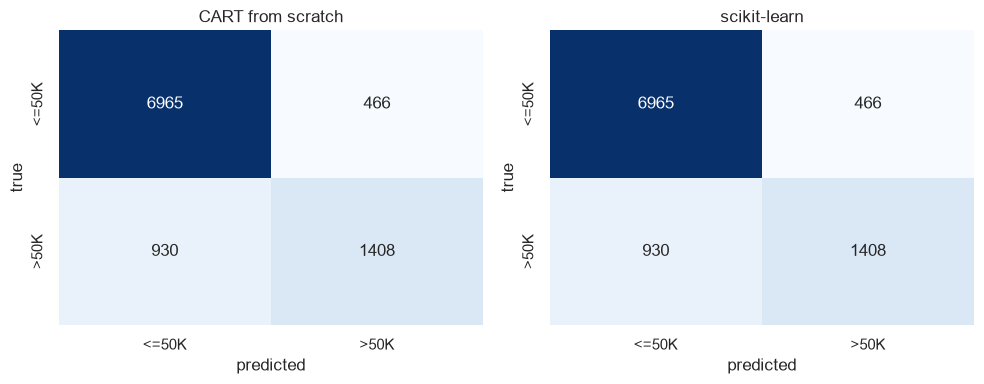

In [11]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4))
for ax, name in zip(axes, ["CART from scratch", "scikit-learn"]):
    cm = confusion_matrix(y_test, preds[name])
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", cbar=False, ax=ax,
                xticklabels=["<=50K", ">50K"], yticklabels=["<=50K", ">50K"])
    ax.set(title=name, xlabel="predicted", ylabel="true")
fig.tight_layout(); fig.savefig(FIG_DIR / "confusion.png", dpi=150); plt.show()

**Result.** On the test set our CART and scikit-learn have **the same accuracy (85.7 %), precision (0.751), recall (0.602) and F1 (0.669)**, far above the baseline (F1 = 0). They agree on 99.98 % of the rows: the 2 differing rows fall in a leaf where both models chose between two features with exactly the same Gini (a tie broken by column order for us, by a random feature order for scikit-learn), which also explains the one large probability gap and the tiny AUC difference. The implementation is therefore correct.

Precision (0.75) is higher than recall (0.60): when the tree says ">50K" it is usually right, but it misses 40 % of the high earners — the expected effect of a 24 % minority class with a 0.5 threshold (section 8.3).

**Cost.** Our training takes ≈ 1 s against ≈ 0.04 s for scikit-learn: about **20× slower**, with the same predictions.

In [12]:
# Cost of training as the training set grows (same hyperparameters)
rows = []
for n in [2000, 4000, 8000, 16000, len(X_train)]:
    for name, make in [("ours", lambda: CARTClassifier(**params)),
                       ("sklearn", lambda: DecisionTreeClassifier(**params, random_state=SEED))]:
        start = time.perf_counter(); make().fit(X_train[:n], y_train[:n])
        rows.append({"n": n, "model": name, "fit time (s)": time.perf_counter() - start})
cost = pd.DataFrame(rows).pivot(index="n", columns="model", values="fit time (s)")
cost["ratio"] = cost["ours"] / cost["sklearn"]
display(cost.round(3))

model,ours,sklearn,ratio
n,,,
2000,0.068,0.003,22.936
4000,0.133,0.006,22.769
8000,0.271,0.012,23.225
16000,0.527,0.023,22.728
29304,0.965,0.043,22.508


Both training times grow roughly linearly with $n$ (the $n \log n$ of the sorts), as expected from the vectorised search. Ours stays one to two orders of magnitude slower: scikit-learn's splitter is compiled Cython, works in place on presorted indices and never copies the data, while ours re-sorts every feature at every node and copies `X[mask]` at each split. The gap is in the **constant**, not in the complexity.

## 7. Answering the question

A one-hot encoded feature is spread over many columns (`marital-status_Married-civ-spouse`, `marital-status_Divorced`, …). To compare *original* variables, the importances of all their columns are summed.

First split of the tree: marital-status_Married-civ-spouse <= 0.5


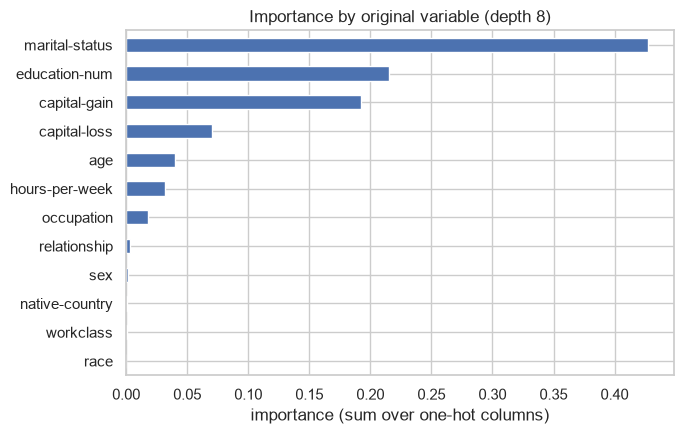

,ours,sklearn
marital-status,0.427,0.427
education-num,0.215,0.215
capital-gain,0.192,0.192
capital-loss,0.070,0.071
age,0.040,0.039
hours-per-week,0.032,0.032
occupation,0.018,0.018
relationship,0.003,0.003
sex,0.001,0.001
native-country,0.001,0.001


In [13]:
final_tree = CARTClassifier(**params).fit(X_train, y_train)

def original(col):
    for c in X_raw.columns:
        if col == c or col.startswith(c + "_"):
            return c
    return col

imp = pd.Series(final_tree.feature_importances_, index=feature_names)
grouped = imp.groupby(imp.index.map(original)).sum().sort_values(ascending=False)
ref_tree = DecisionTreeClassifier(**params, random_state=SEED).fit(X_train, y_train)
grouped_ref = pd.Series(ref_tree.feature_importances_, index=feature_names).groupby(original).sum()

print("First split of the tree:", feature_names[final_tree.root_.feature], "<=", final_tree.root_.threshold)
fig, ax = plt.subplots(figsize=(7, 4.5))
grouped.sort_values().plot.barh(ax=ax)
ax.set(xlabel="importance (sum over one-hot columns)", title=f"Importance by original variable (depth {best_depth})")
fig.tight_layout(); fig.savefig(FIG_DIR / "importance.png", dpi=150); plt.show()
display(pd.DataFrame({"ours": grouped, "sklearn": grouped_ref}).sort_values("ours", ascending=False).round(3))

In [14]:
# A readable depth-3 tree
small = CARTClassifier(max_depth=3).fit(X_train, y_train)
small.print_tree(feature_names)

marital-status_Married-civ-spouse <= 0.50  (n=29304, gini=0.364)
|   capital-gain <= 7055.50  (n=15946, gini=0.119)
|   |   education-num <= 12.50  (n=15678, gini=0.092)
|   |   |   leaf: n=12577, P(>50K)=0.02
|   |   education-num >  12.50
|   |   |   leaf: n=3101, P(>50K)=0.15
|   capital-gain >  7055.50
|   |   age <= 20.50  (n=268, gini=0.079)
|   |   |   leaf: n=5, P(>50K)=0.20
|   |   age >  20.50
|   |   |   leaf: n=263, P(>50K)=0.97
marital-status_Married-civ-spouse >  0.50
|   education-num <= 11.50  (n=13358, gini=0.495)
|   |   capital-gain <= 5095.50  (n=8915, gini=0.439)
|   |   |   leaf: n=8500, P(>50K)=0.29
|   |   capital-gain >  5095.50
|   |   |   leaf: n=415, P(>50K)=0.98
|   education-num >  11.50
|   |   capital-gain <= 5095.50  (n=4443, gini=0.422)
|   |   |   leaf: n=3812, P(>50K)=0.65
|   |   capital-gain >  5095.50
|   |   |   leaf: n=631, P(>50K)=1.00


In [15]:
# Ablation: remove one original variable (all its columns), refit with the same hyperparameters, score on validation.
def columns_of(var):
    return [i for i, c in enumerate(feature_names) if original(c) == var]

def val_scores(keep):
    m = CARTClassifier(**params).fit(X_train[:, keep], y_train)
    return {"val F1": f1_score(y_val, m.predict(X_val[:, keep])),
            "val AUC": roc_auc_score(y_val, m.predict_proba(X_val[:, keep])[:, 1])}

all_cols = list(range(len(feature_names)))
rows = {"(all features)": val_scores(all_cols)}
groups = {"education-num": ["education-num"], "marital-status": ["marital-status"],
          "relationship": ["relationship"], "family (marital + relationship)": ["marital-status", "relationship"],
          "age": ["age"], "hours-per-week": ["hours-per-week"],
          "capital (gain + loss)": ["capital-gain", "capital-loss"], "occupation": ["occupation"]}
for label, vars_ in groups.items():
    drop = sum((columns_of(v) for v in vars_), [])
    rows[f"without {label}"] = val_scores([i for i in all_cols if i not in drop])
ablation = pd.DataFrame(rows).T
ablation["F1 loss"] = ablation.loc["(all features)", "val F1"] - ablation["val F1"]
ablation["AUC loss"] = ablation.loc["(all features)", "val AUC"] - ablation["val AUC"]
display(ablation.sort_values("AUC loss", ascending=False).round(4))

,val F1,val AUC,F1 loss,AUC loss
without family (marital + relationship),0.5567,0.8632,0.1219,0.0468
without capital (gain + loss),0.6365,0.8790,0.0421,0.0310
without education-num,0.6208,0.8976,0.0578,0.0125
without hours-per-week,0.6310,0.9032,0.0477,0.0068
without age,0.6795,0.9053,-0.0008,0.0047
without marital-status,0.6668,0.9064,0.0118,0.0036
without occupation,0.6450,0.9090,0.0337,0.0010
without relationship,0.6790,0.9096,-0.0003,0.0004
(all features),0.6787,0.9100,0.0000,0.0000


In [16]:
# Which variable takes over when one is removed? First split of the tree without each group.
for label, vars_ in [("family", ["marital-status", "relationship"]), ("education", ["education-num"])]:
    drop = sum((columns_of(v) for v in vars_), [])
    keep = [i for i in all_cols if i not in drop]
    m = CARTClassifier(max_depth=1).fit(X_train[:, keep], y_train)
    print(f"without {label}: first split on {feature_names[keep[m.root_.feature]]}")

without family: first split on capital-gain
without education: first split on marital-status_Married-civ-spouse


### What the evidence says

| Evidence | Family situation | Education | Others |
|---|---|---|---|
| Alone (Cramér's V, section 2) | **0.45** (relationship / marital) | 0.36 | occupation 0.35, age 0.32, hours 0.27 |
| First split of the tree | **married (civ-spouse) or not** | — | — |
| Importance, depth 8 (sum of one-hot columns) | **0.43** | 0.22 | capital-gain 0.19, capital-loss 0.07, age 0.04, hours 0.03 |
| Ablation: validation AUC loss | **−0.047** | −0.013 | capital −0.031, hours −0.007, age −0.005 |
| Ablation: validation F1 loss | **−0.122** | −0.058 | hours −0.048, capital −0.042, age ≈ 0 |
| Stable over 5 random splits (8.1) | first split 5/5 | 2nd every time | — |

**Answer.** Our starting hypothesis is **rejected**: in this tree, education is not the main driver. The **family situation** — being married, living with a spouse — is by far the strongest predictor: it is the first question the tree asks, carries twice the importance of education, and removing it hurts performance the most. **Education is clearly the second factor**, ahead of capital income; age and hours worked add little *once marital status and education are known*.

Two details matter for the oral:
- `relationship` gets almost no importance and removing it alone costs nothing, while removing `marital-status` alone costs little too: the two variables carry **the same information** (Husband/Wife ⇔ married). The tree picks one and ignores the other, which is why we grouped them in the ablation.
- Age has little importance but is not irrelevant: it is **absorbed** by marital status (married people are older, section 2). Importance measures what a variable adds *given the others*, not its link with income alone.

**This is prediction, not causation.** Marriage does not "cause" a high income. Marital status is a proxy for several things the data does not separate: age and career stage, sex (in 1994 "Husband" is the large majority of married earners), and possibly household arrangements. `capital-gain` is closer to a *consequence* of wealth than a cause of income. The honest conclusion is: *among the variables of the 1994 census, family situation is the best single predictor of a >50K income, and education the second.*

## 8. Limits: when does the model fail?

### 8.1 Instability
A single tree is a high-variance model: a small change in the training data can change the top splits. We refit the tree on 5 different random splits of the data (seeds 0 to 4) and compare validation scores and importances.

In [17]:
rows, firsts = [], []
for seed in range(5):
    s, names = get_splits(seed=seed)
    m = CARTClassifier(**params).fit(s["X_train"], s["y_train"])
    g = pd.Series(m.feature_importances_, index=names).groupby(lambda c: original(c)).sum()
    rows.append({"seed": seed, "val F1": f1_score(s["y_val"], m.predict(s["X_val"])),
                 "first split": names[m.root_.feature], **g.round(3).to_dict()})
stab = pd.DataFrame(rows).set_index("seed")
display(stab[["val F1", "first split", "marital-status", "relationship", "education-num", "capital-gain", "age", "hours-per-week"]])
print(f"val F1: mean {stab['val F1'].mean():.3f}, std {stab['val F1'].std():.3f}")

,val F1,first split,marital-status,relationship,education-num,capital-gain,age,hours-per-week
seed,,,,,,,,
0,0.653152,marital-status_Married-civ-spouse,0.413,0.002,0.227,0.193,0.037,0.030
1,0.655442,marital-status_Married-civ-spouse,0.417,0.001,0.223,0.197,0.040,0.033
2,0.659130,marital-status_Married-civ-spouse,0.423,0.003,0.226,0.198,0.047,0.032
3,0.637696,marital-status_Married-civ-spouse,0.418,0.003,0.226,0.198,0.049,0.036
4,0.643350,marital-status_Married-civ-spouse,0.417,0.002,0.221,0.199,0.047,0.035


val F1: mean 0.650, std 0.009


The **top of the tree is stable**: the first split is the same for all 5 splits, and the importances of marital status (0.41–0.42), education (0.22–0.23) and capital gain (0.19–0.20) barely move. Our answer to the question does not depend on the random split. The **performance** varies more (validation F1 from 0.638 to 0.659, std 0.009) and so do the deep, small leaves: the variance of a single tree is mostly in its lower levels.

(Each seed draws a new train/validation/test split; only validation scores are reported here, the final test evaluation of section 6 is not repeated.)

### 8.2 Errors by sex

In [18]:
_, X_test_raw, _, _ = __import__("sklearn.model_selection", fromlist=["train_test_split"]).train_test_split(
    X_raw, y_all, test_size=0.2, stratify=y_all, random_state=SEED)   # same rows as splits["X_test"]
sex = X_test_raw["sex"].astype(str).to_numpy()
p = preds["CART from scratch"]
rows = {}
for g in ["Female", "Male"]:
    m = sex == g
    rows[g] = {"n": m.sum(), "share >50K (true)": y_test[m].mean(), "share >50K (predicted)": p[m].mean(),
               "recall": recall_score(y_test[m], p[m]), "precision": precision_score(y_test[m], p[m]),
               "F1": f1_score(y_test[m], p[m])}
display(pd.DataFrame(rows).T.round(3))

,n,share >50K (true),share >50K (predicted),recall,precision,F1
Female,3259.0,0.111,0.075,0.524,0.771,0.624
Male,6510.0,0.304,0.250,0.617,0.748,0.676


The tree is **less good for women**: recall 0.52 against 0.62 for men, F1 0.62 against 0.68. Only 11 % of women in the test set earn >50K (30 % of men), and the main rule of the tree is "married", which for women in this data mostly means "Wife", a smaller and more mixed group. The model learns the 1994 income gap and slightly amplifies it (predicted share 7.5 % vs a true 11.1 % for women). Using such a model for decisions about people (credit, hiring) would require a fairness analysis, not just a global metric.

### 8.3 Decision threshold
`predict` uses $P(>50K) > 0.5$. With imbalanced classes, another threshold can trade precision for recall. The threshold is chosen on the **validation** set.

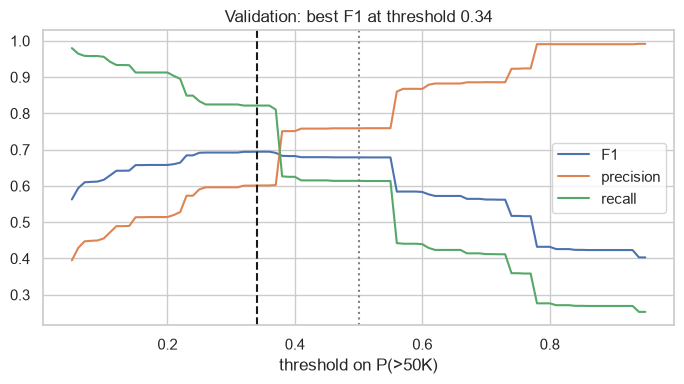

,accuracy,precision,recall,F1
threshold 0.5,0.857,0.751,0.602,0.669
threshold 0.34,0.822,0.594,0.809,0.685


In [19]:
pv = final_tree.predict_proba(X_val)[:, 1]
ths = np.linspace(0.05, 0.95, 91)
f1s = [f1_score(y_val, (pv > t).astype(int)) for t in ths]
best_t = ths[int(np.argmax(f1s))]
fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(ths, f1s, label="F1")
ax.plot(ths, [precision_score(y_val, (pv > t).astype(int), zero_division=0) for t in ths], label="precision")
ax.plot(ths, [recall_score(y_val, (pv > t).astype(int)) for t in ths], label="recall")
ax.axvline(0.5, color="grey", ls=":"); ax.axvline(best_t, color="k", ls="--")
ax.set(xlabel="threshold on P(>50K)", title=f"Validation: best F1 at threshold {best_t:.2f}"); ax.legend()
fig.tight_layout(); fig.savefig(FIG_DIR / "threshold.png", dpi=150); plt.show()
pt = (probas["CART from scratch"] > best_t).astype(int)
display(pd.DataFrame({"threshold 0.5": scores(y_test, preds["CART from scratch"]),
                      f"threshold {best_t:.2f}": scores(y_test, pt)}).T.round(3))

Lowering the threshold from 0.5 to **0.34** (chosen on validation) raises recall from 0.60 to **0.81** and F1 from 0.669 to **0.685** on the test set, at the cost of precision (0.75 → 0.59) and accuracy. The "right" threshold depends on the cost of each error: 0.5 is only optimal for accuracy, not for the minority class.

### 8.4 Structural limits and improvements

- **Axis-aligned cuts.** A tree approximates any oblique or smooth relation (income rising steadily with age) by a staircase; it needs many leaves for what a linear model does with one coefficient.
- **Greedy growth.** Each split is only locally optimal; an interaction that is invisible at the first step (XOR-like) is never found.
- **High variance** (8.1): small data changes, different trees.
- **Importance bias.** Impurity-based importance is measured on the training set and favours features with many thresholds (`capital-gain`, `age`). Permutation importance on the validation set, or the ablation of section 7, are more reliable — this is why we used both.
- **Improvements.** Cost-complexity pruning (implemented, `ccp_alpha`), then ensembles: a **random forest** averages many trees grown on bootstrap samples with random feature subsets (lower variance), **gradient boosting** adds shallow trees fitted to the residual errors (lower bias). Both keep our split search as their building block.

In [20]:
# How much do ensembles of trees gain? (sklearn, for discussion only; same splits, validation set)
from sklearn.ensemble import RandomForestClassifier, HistGradientBoostingClassifier
for name, m in [("random forest (300 trees)", RandomForestClassifier(n_estimators=300, min_samples_leaf=5, n_jobs=-1, random_state=SEED)),
                ("gradient boosting", HistGradientBoostingClassifier(random_state=SEED))]:
    m.fit(X_train, y_train)
    print(f"{name:26s} val F1 = {f1_score(y_val, m.predict(X_val)):.3f}, val AUC = {roc_auc_score(y_val, m.predict_proba(X_val)[:, 1]):.3f}")
print(f"{'our single tree':26s} val F1 = {f1_score(y_val, final_tree.predict(X_val)):.3f}, val AUC = {roc_auc_score(y_val, final_tree.predict_proba(X_val)[:, 1]):.3f}")

random forest (300 trees)  val F1 = 0.681, val AUC = 0.920


gradient boosting          val F1 = 0.719, val AUC = 0.931
our single tree            val F1 = 0.679, val AUC = 0.910


Ensembles do better than one tree, as the course predicts: the random forest mainly gains AUC (0.920 vs 0.910) by averaging away the variance; gradient boosting gains the most (F1 0.719, AUC 0.931) by correcting the bias of shallow trees step by step.

## 9. Conclusion

1. **Implementation.** Our CART from scratch (Gini, vectorised split search, greedy growth, 5 stopping rules, cost-complexity pruning, importances) gives **the same predictions as scikit-learn** on 99.98 % of the test rows and the same metrics (accuracy 85.7 %, F1 0.669, AUC 0.906), for a training time about 20× longer.
2. **Protocol.** Stratified 60/20/20 split, encoding fitted on the train set, depth and leaf size chosen on validation (8 and 5), test used once. F1 and AUC rather than accuracy, which a constant model already sets at 76 %.
3. **Research question.** Education is **not** the main driver of a >50K income in this data. **Family situation (being married) comes first**, education second, then capital income; age and hours worked add little once these are known. This is a predictive association in 1994 data, not a causal effect.
4. **Limits.** A single tree misses 40 % of high earners at the default threshold, is less accurate for women, is unstable in its lower levels and is outperformed by random forests and boosting, which are the natural next step.